# AICE Professional 주피터라이트 실전 모의고사 07회 — 공개데이터(보급 로봇 주행 · 법령 조문 소관부처 · 군용기 기종)

## [ 필독 ] AICE Professional 모의고사 유의사항

- 공식 샘플문항(가공식품 카테고리 분류)과 **같은 시험지 형식**으로 만든 모의고사입니다. 3문항, 180분 기준입니다.
- 공식 시험과 같은 **Tabular / Text / Image 3유형**입니다. 2번 Text 문항은 공식 샘플(상품명 → 카테고리)과 같은 텍스트 분류입니다.
- 본인 스스로 모델을 만들고 **달성 목표 이상의 성능**이 나오도록 개발해야 합니다. 정답(테스트 라벨)은 제공되지 않습니다.
  대신 이 노트북 **맨 마지막 셀**(전체 자동 채점, 정답 키 인코딩)로 제출 파일을 스스로 채점할 수 있습니다(연습용).

## 사용할 수 있는 라이브러리 (주피터라이트 판)

이 모의고사는 **브라우저 주피터라이트(Pyodide · Python 3.14)** 에서 설치 없이 끝까지 풀 수 있도록 라이브러리를 제한했습니다.
필요한 라이브러리는 주피터라이트에 **미리 설치**되어 있습니다. 맨 위 '브라우저 실습' 셀은 확인만 하고 바로 끝납니다(Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다).

| 구분 | 쓸 수 있음 | 쓰지 않음(브라우저에서 안 됨) |
|---|---|---|
| 데이터·그림 | numpy · pandas · matplotlib · seaborn · Pillow | — |
| 머신러닝 | scikit-learn · LightGBM · XGBoost · imbalanced-learn · joblib | CatBoost |
| 텍스트 | scikit-learn 의 CountVectorizer · TfidfVectorizer · 내장 영어 불용어, **NLTK**(불용어·토큰화·어간 추출, 데이터는 `/drive/nltk_data` 에 미리 들어 있음) | 형태소 분석기 · BERT 등 사전학습 언어 모델 |
| 딥러닝 | `tensorflow.keras` 문법(TensorFlow.js 로 실행되는 대체 구현체, 미리 설치): `Sequential`·함수형(`Input` → 층 → `Model`) · Dense · Dropout · BatchNormalization · Conv2D · MaxPooling2D · GlobalAveragePooling2D · Embedding · LSTM · GRU · 콜백 3종(EarlyStopping · ModelCheckpoint · ReduceLROnPlateau) · `load_img` · `img_to_array` · `image_dataset_from_directory` · `ImageDataGenerator` · `model.save` / `load_model` · **MobileNet v1 전이학습**(`alpha=0.25`, 224×224, `weights='imagenet'` 만) | PyTorch · 다른 사전학습 모델(MobileNetV2/V3 · ResNet · EfficientNet 등) · 사용자 정의 층·손실 · GPU |

- 이미지는 64×64 정도로 줄여 작은 CNN 을 직접 학습하거나, MobileNet v1(alpha 0.25)로 특징을 뽑아 분류기를 학습하세요(전이학습). 브라우저 TensorFlow.js 는 CPython TensorFlow 와 수치가 조금 달라 딥러닝 점수가 약간 다르게 나올 수 있습니다.
- 학습이 오래 걸리면 epoch 를 줄이거나 조기 종료(EarlyStopping)를 쓰세요. 최신 Chrome·Edge 를 권장합니다.

## 시간 배분(180분)

| 문항 | 권장 시간 | 먼저 할 일 |
|---|---|---|
| 1. Tabular (30점) | 50분 | `info()`·`describe()` 로 자료형·결측 확인 → 기본 모델로 제출 파일부터 만들기 |
| 2. Text (35점) | 60분 | 라벨 분포·문장 길이 확인 → TF-IDF + 선형 모델로 기준 점수 |
| 3. Image (35점) | 60분 | 압축 풀기·폴더 구조 확인 → 작은 CNN 으로 기준 점수 |
| 마무리 | 10분 | 제출 파일 6개 이름·열 구조 확인 → 맨 마지막 채점 셀 실행 |

## 시험 자원 가이드

| 구분 | 공식 시험 | 이 모의고사 |
|---|---|---|
| IDE | CPU 8 core · Memory 32G · GPU 1개(VRAM 16GB) | **브라우저 주피터라이트**(설치 없음, CPU) — Colab·로컬 Jupyter 에서도 그대로 실행됨 |
| SW | Python 3.10 · TensorFlow 2.13 · PyTorch 2.1 | Python 3.14(Pyodide) · scikit-learn · LightGBM · XGBoost · Keras 문법(TensorFlow.js) — 위 표의 라이브러리만 |

## 유의 사항

- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 제출 파일명은 **고정**입니다: `answer_1~3` 모델 파일과 `answer_1~3.csv`.


문제에 제시되는 가이드는 필수적으로 준수하여 주시기 바랍니다. 이를 준수하지 않을 경우 채점 제한 또는 0점 처리될 수 있으니
각별히 유의해 주시기 바랍니다.

#### **[학습 정보]**
- 학습 목표 : Tabular · Text · Image 예측 모델 3종을 만들어 달성 목표 이상의 예측 파일을 제출하고, 제출한 코드로 같은 모델이 재현되게 할 수 있다
- AICE 역량 : PT1·PT2 표 데이터 / PX1·PX2 텍스트 / PI1·PI2 이미지 / PS1 제출 파일 형식·재현성
- 제출 파일 : `answer_1~3` 모델 파일(.pkl · .h5 등)과 `answer_1~3.csv` — **파일명은 고정**입니다(이름을 바꾸면 채점되지 않음)

| 문항 | 문제 | 달성 목표 | 역량 | 기술 | 예상 시간 |
|---|---|---|---|---|---|
| 1. Tabular | 보급 로봇 주행 명령 분류(결측·이상치) | 정확도 0.93 이상 | PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | pandas, scikit-learn(RandomForestClassifier), joblib | 50분 |
| 2. Text | 법령 조문 소관부처 분류 | 정확도 0.76 이상 | PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | pandas, scikit-learn(TfidfVectorizer, LinearSVC), joblib | 60분 |
| 3. Image | 군용기 기종 이미지 분류(5종) | 정확도 0.46 이상 | PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | pandas, Keras(TensorFlow.js) | 60분 |

In [1]:
# (브라우저 실습) 주피터라이트에는 tensorflow(TensorFlow.js 대체 구현체)·scikit-learn·LightGBM 등이 미리 설치되어 있어 이 셀은 확인만 합니다.
# Colab·로컬 Jupyter 에서는 아무 일도 하지 않습니다.
import os, sys, importlib.util
if 'pyodide' in sys.modules:
    os.environ['AICE_IMG_DIR'] = '/tmp/aice_images/' + os.path.basename(os.getcwd())   # 이미지 압축은 메모리 폴더에 풂(빠름)
    if not ('tensorflow' in sys.modules or importlib.util.find_spec('tensorflow')):
        # 미리 설치되지 않은 사이트(패치 전 주피터라이트)에서만: 같은 폴더의 tfjs_keras.py 를 불러옵니다
        sys.path[:0] = [os.getcwd(), '/drive']
        import tfjs_keras
        await tfjs_keras.load()
print('준비 완료 — 다음 셀로 넘어가세요.')

준비 완료 — 다음 셀로 넘어가세요.


## 1. Tabular 문제 - 보급 로봇 주행 명령 분류(결측·이상치) (30점)

<sub>학습 목표: 보급 로봇 주행 명령 분류(결측·이상치) 모델로 테스트 정확도 0.93 이상을 달성할 수 있다 | 역량: PT1 표 데이터 전처리·피처 엔지니어링, PT2 표 데이터 모델 학습·평가 | 기술: pandas, scikit-learn(RandomForestClassifier), joblib | 난이도: 중급 | 예상 시간: 50분</sub>

### 문제 개요

물자 보급용 무인 운반 로봇이 초음파 센서 24개 값으로 **다음 주행 명령 4종** 을 정하는 분류 문제입니다. 센서 통신이 끊긴 **결측값** 과 센서 오류로 찍힌 **이상값(99)** 이 섞여 있어, 정리부터 해야 합니다.

제공된 훈련 데이터셋을 활용해 다중 분류(4종) 모델을 개발하고, 테스트 데이터셋의 'command' 값을 예측하시기 바랍니다.

### 달성 목표

"01_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 93% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `01_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `01_test_x.csv`: 테스트 데이터셋입니다. 라벨('command') 값이 제외되어 있습니다.

**Label 정보**

- 'command' : Move-Forward / Slight-Right-Turn / Sharp-Right-Turn / Slight-Left-Turn

**Data 정보**

- 'id' : 기록 번호
- 'zone' : 운행 구역(A·B·C) — 주행 명령과 관계없이 기록된 값
- 'US1 ~ US24' : 로봇 둘레 초음파 센서 24개의 거리(m), 정상 범위 약 0.4~5. 결측(빈칸)·오류값 99 가 섞여 있음

**데이터 출처** — UCI Wall-Following Robot Navigation(HF mstz/wall_following, CC BY 4.0) — 결측(4%)·센서 오류값 99(1%)을 일부러 넣음

### 데이터 예시

`01_train.csv`

| id | zone | US1 | US2 | US3 | US4 | US5 | US6 | … |
|---|---|---|---|---|---|---|---|---|
| 1098 | A | 1.335 | 1.349 | 1.57 | 1.922 | 1.959 | 1.815 | … |
| 4490 | B | 2.562 | 2.641 | 2.435 | 1.335 | 1.308 | 1.286 | … |
| 374 | B | 1.148 | 5 | 2.471 | 2.47 |  | 2.69 | … |

`01_test_x.csv`

| id | zone | US1 | US2 | US3 | US4 | US5 | US6 | … |
|---|---|---|---|---|---|---|---|---|
| 2823 | A | 1.309 | 4.72 | 4.125 | 5 | 5 | 2.387 | … |
| 1918 | A | 0.604 | 0.648 | 1.253 | 1.396 | 1.386 | 1.405 | … |
| 737 | B | 1.415 | 1.413 | 2.356 | 1.818 | 1.812 | 1.82 | … |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 보급 로봇 주행 명령 분류(결측·이상치) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_1.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('command') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_1.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'command' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'command' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- `isna().sum()` 과 `describe()` 로 결측·이상값을 먼저 확인하세요.
- **테스트 행은 지우면 안 됩니다**(제출 행 수가 모자라면 0점). 학습 데이터는 결측 행을 지워도 되지만, 테스트는 반드시 값을 채워야 합니다.
- 이상값 99 는 결측으로 바꾼 뒤(`replace(99, np.nan)`) 학습 데이터의 중앙값으로 채우는 방법이 간단합니다. 중앙값은 **학습 데이터에서만** 구합니다.
- 평가 지표는 **정확도(Accuracy)** 입니다.

### 채점 진행 방식 안내

- 1번 문항 배점 : 30점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_1.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 83.7% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [2]:

import os
import shutil
import pandas as pd

if not os.path.exists('01_test_x.csv') and os.path.exists('01_test_x(1).csv'):
    shutil.copy2('01_test_x(1).csv', '01_test_x.csv')

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')

SENS = [f'US{i}' for i in range(1, 25)]

print('학습 데이터:', train.shape)
print('테스트 데이터:', test.shape)

print('\n컬럼 및 자료형:')
print(train.dtypes)

print('\n정답 분포:')
print(pd.DataFrame({
    '건수': train['command'].value_counts(),
    '비율(%)': (train['command'].value_counts(normalize=True) * 100).round(2)
}))

print('\n센서 결측치 및 이상값:')
print(pd.DataFrame({
    '학습': [train[SENS].isna().sum().sum(), (train[SENS] == 99).sum().sum()],
    '테스트': [test[SENS].isna().sum().sum(), (test[SENS] == 99).sum().sum()]
}, index=['결측치', '이상값(99)']))

print('\n센서별 결측치 상위 10개:')
print(train[SENS].isna().sum().sort_values(ascending=False).head(10))

print('\n센서 기초 통계:')
display(train[SENS[:6]].describe().round(3))

print('\n데이터 미리보기:')
display(train.head(3))


학습 데이터: (4364, 27)
테스트 데이터: (1092, 26)

컬럼 및 자료형:
id           int64
zone        object
US1        float64
US2        float64
US3        float64
US4        float64
US5        float64
US6        float64
US7        float64
US8        float64
US9        float64
US10       float64
US11       float64
US12       float64
US13       float64
US14       float64
US15       float64
US16       float64
US17       float64
US18       float64
US19       float64
US20       float64
US21       float64
US22       float64
US23       float64
US24       float64
command     object
dtype: object

정답 분포:
                     건수  비율(%)
command                       
Sharp-Right-Turn   1764  40.42
Slight-Right-Turn  1677  38.43
Move-Forward        661  15.15
Slight-Left-Turn    262   6.00

센서 결측치 및 이상값:
           학습   테스트
결측치      4204  1102
이상값(99)   966   274

센서별 결측치 상위 10개:
US8     197
US4     195
US7     193
US24    192
US18    190
US20    188
US22    181
US16    180
US13    180
US15    179
dtype: int64

센서 

,US1,US2,US3,US4,US5,US6
count,4192.000,4193.000,4205.000,4169.000,4200.000,4196.000
mean,2.609,2.865,3.710,3.713,3.887,4.002
std,10.514,7.427,10.839,9.353,9.423,10.300
min,0.401,0.437,0.470,0.833,1.120,1.114
25%,0.921,1.367,1.547,1.747,1.781,1.798
50%,1.339,1.903,2.086,2.498,2.682,2.708
75%,1.859,2.689,2.844,4.147,4.754,4.122
max,99.000,99.000,99.000,99.000,99.000,99.000



데이터 미리보기:


,id,zone,US1,US2,US3,US4,US5,US6,US7,US8,...,US16,US17,US18,US19,US20,US21,US22,US23,US24,command
0,1098,A,1.335,1.349,1.570,1.922,1.959,1.815,3.234,5.000,...,0.844,0.571,0.460,0.451,0.462,0.477,0.500,1.065,1.347,Move-Forward
1,4490,B,2.562,2.641,2.435,1.335,1.308,1.286,1.275,1.284,...,0.914,0.957,0.848,NaN,5.000,4.413,3.660,2.643,2.625,Slight-Right-Turn
2,374,B,1.148,5.000,2.471,2.470,NaN,2.690,2.244,2.157,...,0.742,0.730,0.738,0.759,0.878,0.831,0.771,1.007,0.950,Slight-Right-Turn


In [3]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = train[SENS].replace(99, np.nan).copy()
y = train['command'].copy()
X_test_raw = test[SENS].replace(99, np.nan).copy()

X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=SENS,
    index=X_train_raw.index
)

X_valid = pd.DataFrame(
    imputer.transform(X_valid_raw),
    columns=SENS,
    index=X_valid_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=SENS,
    index=X_test_raw.index
)

print('학습:', X_train.shape)
print('검증:', X_valid.shape)
print('테스트:', X_test.shape)

print('\n전처리 후 결측치:')
print('학습:', X_train.isna().sum().sum())
print('검증:', X_valid.isna().sum().sum())
print('테스트:', X_test.isna().sum().sum())

print('\n학습·검증 클래스 비율(%):')
print(pd.DataFrame({
    '학습': (y_train.value_counts(normalize=True) * 100).round(2),
    '검증': (y_valid.value_counts(normalize=True) * 100).round(2)
}))

print('\n학습 데이터 기준 센서 중앙값:')
display(pd.Series(imputer.statistics_, index=SENS).head(10))


학습: (3491, 24)
검증: (873, 24)
테스트: (1092, 24)

전처리 후 결측치:
학습: 0
검증: 0
테스트: 0

학습·검증 클래스 비율(%):
                      학습     검증
command                        
Sharp-Right-Turn   40.42  40.44
Slight-Right-Turn  38.41  38.49
Move-Forward       15.15  15.12
Slight-Left-Turn    6.02   5.96

학습 데이터 기준 센서 중앙값:


,0
US1,1.3370
US2,1.9170
US3,2.0670
US4,2.4840
US5,2.6785
US6,2.6870
US7,3.2315
US8,2.1680
US9,2.7975
US10,2.6810


In [4]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import accuracy_score, classification_report

candidates = {
    'RandomForest': RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    'ExtraTrees': ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.06,
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []
fitted_models = {}

for name, model in candidates.items():
    pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', model)
    ])

    scores = cross_val_score(
        pipe,
        X_train_raw,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=1
    )

    pipe.fit(X_train_raw, y_train)
    valid_pred = pipe.predict(X_valid_raw)
    valid_acc = accuracy_score(y_valid, valid_pred)

    results.append({
        '모델': name,
        'CV 평균 정확도': scores.mean(),
        'CV 표준편차': scores.std(),
        '검증 정확도': valid_acc
    })

    fitted_models[name] = pipe

comparison = pd.DataFrame(results).sort_values(
    'CV 평균 정확도',
    ascending=False
)

display(comparison.round(4))

best_name = comparison.iloc[0]['모델']
best_model = fitted_models[best_name]

print('\nCV 기준 최고 모델:', best_name)

print('\n클래스별 검증 성능:')
print(classification_report(
    y_valid,
    best_model.predict(X_valid_raw),
    zero_division=0
))


,모델,CV 평균 정확도,CV 표준편차,검증 정확도
2,HistGradientBoosting,0.9828,0.0040,0.9840
0,RandomForest,0.9825,0.0033,0.9805
1,ExtraTrees,0.9590,0.0053,0.9542



CV 기준 최고 모델: HistGradientBoosting

클래스별 검증 성능:
                   precision    recall  f1-score   support

     Move-Forward       1.00      0.96      0.98       132
 Sharp-Right-Turn       0.96      1.00      0.98       353
 Slight-Left-Turn       1.00      0.98      0.99        52
Slight-Right-Turn       1.00      0.98      0.99       336

         accuracy                           0.98       873
        macro avg       0.99      0.98      0.98       873
     weighted avg       0.98      0.98      0.98       873



In [5]:

import os
import joblib
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

X_full = train[SENS].replace(99, np.nan)
y_full = train['command']
X_test_final = test[SENS].replace(99, np.nan)

final_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.06,
        random_state=42
    ))
])

final_model.fit(X_full, y_full)

pred_before = final_model.predict(X_test_final)

version = 1
while (
    os.path.exists(f'candidate_1_v{version}.pkl')
    or os.path.exists(f'candidate_1_v{version}.csv')
):
    version += 1

model_path = f'candidate_1_v{version}.pkl'
csv_path = f'candidate_1_v{version}.csv'

joblib.dump(final_model, model_path)
loaded_model = joblib.load(model_path)

pred_after = loaded_model.predict(X_test_final)

assert np.array_equal(pred_before, pred_after)

candidate = test.copy()
candidate['command'] = pred_after

candidate.to_csv(csv_path, index=False)

check = pd.read_csv(csv_path)

assert check.shape == (len(test), len(test.columns) + 1)
assert check.columns.tolist() == test.columns.tolist() + ['command']
assert check['command'].notna().all()
assert set(check['command']).issubset(set(y_full.unique()))
assert np.array_equal(check['command'].to_numpy(), pred_after)

pd.testing.assert_frame_equal(
    check[test.columns],
    test,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

print('전체 학습 데이터:', X_full.shape)
print('테스트 예측 데이터:', check.shape)
print('모델 파일:', model_path)
print('CSV 파일:', csv_path)
print('저장 전후 예측 일치:', np.array_equal(pred_before, pred_after))
print('CSV 검증: 통과')

print('\n테스트 예측 분포:')
print(check['command'].value_counts())

print('\n예측 CSV 미리보기:')
display(check.head(3))


전체 학습 데이터: (4364, 24)
테스트 예측 데이터: (1092, 27)
모델 파일: candidate_1_v1.pkl
CSV 파일: candidate_1_v1.csv
저장 전후 예측 일치: True
CSV 검증: 통과

테스트 예측 분포:
command
Sharp-Right-Turn     454
Slight-Right-Turn    414
Move-Forward         161
Slight-Left-Turn      63
Name: count, dtype: int64

예측 CSV 미리보기:


,id,zone,US1,US2,US3,US4,US5,US6,US7,US8,...,US16,US17,US18,US19,US20,US21,US22,US23,US24,command
0,2823,A,1.309,4.720,4.125,5.000,5.000,2.387,2.37,1.651,...,0.622,0.598,0.589,99.000,0.751,5.000,1.202,5.000,1.299,Slight-Right-Turn
1,1918,A,0.604,0.648,1.253,1.396,1.386,1.405,5.00,1.445,...,0.731,0.719,0.726,0.751,0.775,0.594,0.577,0.566,0.575,Sharp-Right-Turn
2,737,B,1.415,1.413,2.356,1.818,1.812,1.820,5.00,1.861,...,5.000,1.926,0.491,0.575,0.531,1.382,1.369,1.356,1.385,Move-Forward


In [6]:

import os
import shutil
import filecmp
import joblib
import numpy as np
import pandas as pd

source_model = 'candidate_1_v1.pkl'
source_csv = 'candidate_1_v1.csv'

target_model = 'answer_1.pkl'
target_csv = 'answer_1.csv'

test_check = pd.read_csv('01_test_x.csv')
candidate_check = pd.read_csv(source_csv)
model_check = joblib.load(source_model)

assert candidate_check.shape == (1092, 27)
assert candidate_check.columns.tolist() == test_check.columns.tolist() + ['command']

pd.testing.assert_frame_equal(
    candidate_check[test_check.columns],
    test_check,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

pred_check = model_check.predict(
    test_check[SENS].replace(99, np.nan)
)

assert np.array_equal(
    pred_check,
    candidate_check['command'].to_numpy()
)

for source, target in [
    (source_model, target_model),
    (source_csv, target_csv)
]:
    if os.path.exists(target):
        assert filecmp.cmp(source, target, shallow=False), (
            f'{target}에 다른 파일이 이미 존재합니다.'
        )
        print('기존 파일 일치:', target)
    else:
        shutil.copy2(source, target)
        print('정식 파일 생성:', target)

assert filecmp.cmp(source_model, target_model, shallow=False)
assert filecmp.cmp(source_csv, target_csv, shallow=False)

print('\n제출 모델:', target_model)
print('제출 CSV:', target_csv)
print('CSV 행 수:', len(candidate_check))
print('저장 모델 예측 일치:', True)
print('최종 제출 파일 검증: 통과')


정식 파일 생성: answer_1.pkl
정식 파일 생성: answer_1.csv

제출 모델: answer_1.pkl
제출 CSV: answer_1.csv
CSV 행 수: 1092
저장 모델 예측 일치: True
최종 제출 파일 검증: 통과


<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

클래스 분포를 확인하고, 범주형은 원-핫 인코딩합니다. 값의 크기가 다르면 선형 모델 앞에 표준화를 두고, 트리 모델과 **교차검증 정확도** 로 비교하세요.

- 이 문항의 핵심: `isna().sum()` 과 `describe()` 로 결측·이상값을 먼저 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `pandas`, `joblib`, `RandomForestClassifier`, `train_test_split`, `accuracy_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 1번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.ensemble import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

train = pd.read_csv('01_train.csv')
test = pd.read_csv('01_test_x.csv')
SENS = [f'____' for i in range(____, ____)]
print('____', int(train[SENS].isna().sum().sum()), '____', int((train[SENS] == ____).sum().sum()))
print(train[SENS[:____]].describe().round(____))


# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_1.pkl`(모델) · `answer_1.csv`(예측)

</details>

## 2. Text 문제 - 법령 조문 소관부처 분류 (35점)

<sub>학습 목표: 법령 조문 소관부처 분류 모델로 테스트 정확도 0.76 이상을 달성할 수 있다 | 역량: PX1 텍스트 정제·벡터화, PX2 텍스트 분류 모델 학습·평가 | 기술: pandas, scikit-learn(TfidfVectorizer, LinearSVC), joblib | 난이도: 실전 | 예상 시간: 60분</sub>

### 문제 개요

법령의 조문(제목·내용) 텍스트로 그 법령을 맡은 **소관부처** 를 분류하는 자연어 처리(Text Classification) 문제입니다. 공식 샘플문항(가공식품 상품명 → 카테고리)과 같은 형식입니다.

제공된 훈련 데이터셋을 활용해 텍스트 다중 분류(6종) 모델을 개발하고, 테스트 데이터셋의 '소관부처' 값을 예측하시기 바랍니다.

### 달성 목표

"02_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 76% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `02_train.csv`: 훈련 데이터셋입니다. 훈련 데이터셋으로 모델을 만드세요.
- `02_test_x.csv`: 테스트 데이터셋입니다. 라벨('소관부처') 값이 제외되어 있습니다.

**Label 정보**

- '소관부처' : 국방부 / 국토교통부 / 보건복지부 / 고용노동부 / 환경부 / 산업통상자원부

**Data 정보**

- '조문제목' : 조문의 제목(예: 목적, 정의, 벌칙)
- '조문내용' : 조문 본문(앞 300자)
- 'id' : 테스트 행 번호(테스트에만)

**데이터 출처** — 한국 법령 조문(HF smhilee/korean-law-dataset) — 6개 부처 조문, 조문 내용은 앞 300자

### 데이터 예시

`02_train.csv`

| 조문제목 | 조문내용 | 소관부처 |
|---|---|---|
| 종전 수출자유지역의 국가산업단지 간주에 관한 특례 | 제50조의2(종전 수출자유지역의 국가산업단지 간주에 관한 특례) 종전의 「수출자유지역설치법」(2000년 1월 12일 법률 제6142호로 전부개정되기 전의 것을 말한다)에 따라 지정된 수출자유지역은 「산업입지 및 개발에 관한 법률」 제6조에도 불구하고 같은 법 제2조제8호가목의 국가산업단지로 본다. | 산업통상자원부 |
| 석유생산장치의 평행추 | 제63조(석유생산장치의 평행추) 석유생산장치의 평행추는 낙하하지 아니하도록 하여야 한다. | 산업통상자원부 |
| 청정생산지원센터의 사업 | 제7조(청정생산지원센터의 사업) 법 제7조제2항제5호에서 "그 밖에 청정생산 지원과 관련하여 산업통상자원부령으로 정하는 사업"이란 청정생산의 지원과 제품의 환경친화성 제고를 위한 조사 및 연구사업을 말한다. <개정 2013.3.23> | 산업통상자원부 |

`02_test_x.csv`

| id | 조문제목 | 조문내용 |
|---|---|---|
| 1 | 관련 단체에 대한 재정지원 | 제18조(관련 단체에 대한 재정지원) |
| 2 |  |                   제9절 감사 <개정 2009.11.6> |
| 3 | 분출시 대비훈련 | 제131조(분출시 대비훈련) 해상시추리그의 모든 광산근로자에 대하여 석유분출시를 대비한 대비훈련을 실시하여야 한다. |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 법령 조문 소관부처 분류 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_2.pkl** (또는 다른 확장자의 모델 파일)

(2) 라벨('소관부처') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_2.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 '소관부처' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 '소관부처' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 한국어는 조사·어미가 붙어 단어가 여러 모양으로 나옵니다. **문자 n-gram**(TfidfVectorizer(analyzer='char_wb'))이 잘 맞습니다.
- 학습 라벨 분포: 산업통상자원부 1200, 보건복지부 1200, 국토교통부 1200, 환경부 1160, 국방부 965, 고용노동부 461
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트 행 순서(`id`)를 그대로 유지해 제출하세요.

### 채점 진행 방식 안내

- 2번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_2.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 68.4% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

In [8]:

import pandas as pd

train2 = pd.read_csv('02_train.csv')
test2 = pd.read_csv('02_test_x.csv')

print('학습 데이터:', train2.shape)
print('테스트 데이터:', test2.shape)

print('\n컬럼 및 자료형:')
print(train2.dtypes)

print('\n결측치:')
print(pd.DataFrame({
    '학습': train2.isna().sum(),
    '테스트': test2.isna().sum()
}))

print('\n정답 분포:')
print(pd.DataFrame({
    '건수': train2['소관부처'].value_counts(),
    '비율(%)': (
        train2['소관부처'].value_counts(normalize=True) * 100
    ).round(2)
}))

print('\n텍스트 길이 통계:')
for col in ['조문제목', '조문내용']:
    print(f'\n{col}')
    print(pd.DataFrame({
        '학습': train2[col].fillna('').str.len().describe(),
        '테스트': test2[col].fillna('').str.len().describe()
    }).round(1))

print('\n학습 데이터 미리보기:')
display(train2.head(5))

print('\n테스트 데이터 미리보기:')
display(test2.head(3))


학습 데이터: (6186, 3)
테스트 데이터: (1547, 3)

컬럼 및 자료형:
조문제목    object
조문내용    object
소관부처    object
dtype: object

결측치:
         학습    테스트
id      NaN    0.0
소관부처    0.0    NaN
조문내용    0.0    0.0
조문제목  678.0  171.0

정답 분포:
           건수  비율(%)
소관부처                
산업통상자원부  1200  19.40
보건복지부    1200  19.40
국토교통부    1200  19.40
환경부      1160  18.75
국방부       965  15.60
고용노동부     461   7.45

텍스트 길이 통계:

조문제목
           학습     테스트
count  6186.0  1547.0
mean     11.6    11.6
std       7.6     7.6
min       0.0     0.0
25%       5.0     5.0
50%      13.0    12.0
75%      17.0    17.0
max      46.0    36.0

조문내용
           학습     테스트
count  6186.0  1547.0
mean     73.9    72.1
std      57.8    55.7
min      20.0    20.0
25%      25.0    25.0
50%      59.0    55.0
75%     107.0   104.0
max     300.0   300.0

학습 데이터 미리보기:


,조문제목,조문내용,소관부처
0,종전 수출자유지역의 국가산업단지 간주에 관한 특례,제50조의2(종전 수출자유지역의 국가산업단지 간주에 관한 특례) 종전의 「수출자유지...,산업통상자원부
1,석유생산장치의 평행추,제63조(석유생산장치의 평행추) 석유생산장치의 평행추는 낙하하지 아니하도록 하여야 한다.,산업통상자원부
2,청정생산지원센터의 사업,"제7조(청정생산지원센터의 사업) 법 제7조제2항제5호에서 ""그 밖에 청정생산 지원과...",산업통상자원부
3,피해자단체 사업의 지원,제14조의2(피해자단체 사업의 지원),환경부
4,관리사업자의 지원사업의 재원 및 시행기간 등,제25조(관리사업자의 지원사업의 재원 및 시행기간 등),산업통상자원부



테스트 데이터 미리보기:


,id,조문제목,조문내용
0,1,관련 단체에 대한 재정지원,제18조(관련 단체에 대한 재정지원)
1,2,NaN,제9절 감사 <개정 2009.11.6>
2,3,분출시 대비훈련,제131조(분출시 대비훈련) 해상시추리그의 모든 광산근로자에 대하여 석유분출시를 대...


In [9]:

from sklearn.model_selection import train_test_split

def prepare_text(df):
    title = df['조문제목'].fillna('').astype(str)
    content = df['조문내용'].fillna('').astype(str)

    combined = title + ' ' + content
    return combined.str.replace(r'\s+', ' ', regex=True).str.strip()

X2_full = prepare_text(train2)
y2_full = train2['소관부처'].copy()
X2_test = prepare_text(test2)

X2_train, X2_valid, y2_train, y2_valid = train_test_split(
    X2_full,
    y2_full,
    test_size=0.2,
    random_state=42,
    stratify=y2_full
)

print('학습:', X2_train.shape)
print('검증:', X2_valid.shape)
print('테스트:', X2_test.shape)

print('\n학습·검증 클래스 비율(%):')
print(pd.DataFrame({
    '학습': (y2_train.value_counts(normalize=True) * 100).round(2),
    '검증': (y2_valid.value_counts(normalize=True) * 100).round(2)
}))

print('\n전처리 후 빈 텍스트:')
print('학습:', (X2_train.str.len() == 0).sum())
print('검증:', (X2_valid.str.len() == 0).sum())
print('테스트:', (X2_test.str.len() == 0).sum())

print('\n전처리된 텍스트 예시:')
for text in X2_train.head(3):
    print(text[:200])
    print()


학습: (4948,)
검증: (1238,)
테스트: (1547,)

학습·검증 클래스 비율(%):
            학습     검증
소관부처                 
고용노동부     7.44   7.51
국방부      15.60  15.59
국토교통부    19.40  19.39
보건복지부    19.40  19.39
산업통상자원부  19.40  19.39
환경부      18.76  18.74

전처리 후 빈 텍스트:
학습: 0
검증: 0
테스트: 0

전처리된 텍스트 예시:
방위산업 국가정책사업의 지정 대상 및 절차 제5조(방위산업 국가정책사업의 지정 대상 및 절차)

시험 실시 결과 보고 제17조(시험 실시 결과 보고) 영 제20조에 따른 시험 실시 결과의 보고나 통보는 최종 합격자를 발표한 날부터 10일 이내에 별지 제6호서식의 시험 실시 결과 보고(통보)서에 따라 하여야 한다.

전기안전점검 결과의 기록 등 제19조(전기안전점검 결과의 기록 등) 법 제13조제3항에 따라 안전공사가 전기안전점검을 한 경우에는 다음 각 호의 사항을 적은 서류 또는 자료를 3년간 보존해야 한다.



In [10]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report

candidates2 = {
    'Char TF-IDF + LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=120000
        )),
        ('model', LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ]),
    'Word TF-IDF + LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ('model', LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        ))
    ]),
    'Char TF-IDF + LogisticRegression': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='char_wb',
            ngram_range=(2, 5),
            min_df=2,
            sublinear_tf=True,
            max_features=120000
        )),
        ('model', LogisticRegression(
            max_iter=1500,
            random_state=42
        ))
    ]),
    'Word TF-IDF + MultinomialNB': Pipeline([
        ('tfidf', TfidfVectorizer(
            analyzer='word',
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ('model', MultinomialNB(alpha=0.5))
    ])
}

cv2 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

results2 = []
fitted_models2 = {}

for name, pipe in candidates2.items():
    scores = cross_val_score(
        pipe,
        X2_train,
        y2_train,
        cv=cv2,
        scoring='accuracy',
        n_jobs=1
    )

    pipe.fit(X2_train, y2_train)
    valid_pred = pipe.predict(X2_valid)

    results2.append({
        '모델': name,
        'CV 평균 정확도': scores.mean(),
        'CV 표준편차': scores.std(),
        '검증 정확도': accuracy_score(y2_valid, valid_pred),
        '검증 Macro F1': f1_score(
            y2_valid, valid_pred, average='macro'
        )
    })

    fitted_models2[name] = pipe

comparison2 = pd.DataFrame(results2).sort_values(
    'CV 평균 정확도',
    ascending=False
)

display(comparison2.round(4))

best_name2 = comparison2.iloc[0]['모델']
best_model2 = fitted_models2[best_name2]

print('\nCV 기준 최고 모델:', best_name2)

print('\n클래스별 검증 성능:')
print(classification_report(
    y2_valid,
    best_model2.predict(X2_valid),
    zero_division=0
))


,모델,CV 평균 정확도,CV 표준편차,검증 정확도,검증 Macro F1
0,Char TF-IDF + LinearSVC,0.7724,0.0085,0.8078,0.8101
2,Char TF-IDF + LogisticRegression,0.7340,0.0064,0.7674,0.7577
1,Word TF-IDF + LinearSVC,0.5168,0.0113,0.5687,0.5672
3,Word TF-IDF + MultinomialNB,0.4733,0.0184,0.5186,0.4947



CV 기준 최고 모델: Char TF-IDF + LinearSVC

클래스별 검증 성능:
              precision    recall  f1-score   support

       고용노동부       0.89      0.73      0.80        93
         국방부       0.90      0.87      0.88       193
       국토교통부       0.74      0.76      0.75       240
       보건복지부       0.77      0.86      0.81       240
     산업통상자원부       0.80      0.79      0.80       240
         환경부       0.82      0.81      0.81       232

    accuracy                           0.81      1238
   macro avg       0.82      0.80      0.81      1238
weighted avg       0.81      0.81      0.81      1238



In [11]:

import os
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone

final_model2 = clone(best_model2)
final_model2.fit(X2_full, y2_full)

pred_before2 = final_model2.predict(X2_test)

version2 = 1
while (
    os.path.exists(f'candidate_2_v{version2}.pkl')
    or os.path.exists(f'candidate_2_v{version2}.csv')
):
    version2 += 1

model_path2 = f'candidate_2_v{version2}.pkl'
csv_path2 = f'candidate_2_v{version2}.csv'

joblib.dump(final_model2, model_path2)
loaded_model2 = joblib.load(model_path2)

pred_after2 = loaded_model2.predict(X2_test)

assert np.array_equal(pred_before2, pred_after2)

candidate2 = test2.copy()
candidate2['소관부처'] = pred_after2

candidate2.to_csv(csv_path2, index=False)

check2 = pd.read_csv(csv_path2)

assert check2.shape == (len(test2), len(test2.columns) + 1)
assert check2.columns.tolist() == test2.columns.tolist() + ['소관부처']
assert check2['소관부처'].notna().all()
assert set(check2['소관부처']).issubset(set(y2_full.unique()))
assert np.array_equal(
    check2['소관부처'].to_numpy(),
    pred_after2
)

pd.testing.assert_frame_equal(
    check2[test2.columns],
    test2.reset_index(drop=True)
)

print('전체 학습 데이터:', X2_full.shape)
print('테스트 예측 데이터:', check2.shape)
print('모델 파일:', model_path2)
print('CSV 파일:', csv_path2)
print('저장 전후 예측 일치:', np.array_equal(pred_before2, pred_after2))
print('CSV 검증: 통과')

print('\n테스트 예측 분포:')
print(check2['소관부처'].value_counts())

print('\n예측 CSV 미리보기:')
display(check2.head(3))


전체 학습 데이터: (6186,)
테스트 예측 데이터: (1547, 4)
모델 파일: candidate_2_v1.pkl
CSV 파일: candidate_2_v1.csv
저장 전후 예측 일치: True
CSV 검증: 통과

테스트 예측 분포:
소관부처
환경부        310
보건복지부      308
산업통상자원부    302
국토교통부      301
국방부        235
고용노동부       91
Name: count, dtype: int64

예측 CSV 미리보기:


,id,조문제목,조문내용,소관부처
0,1,관련 단체에 대한 재정지원,제18조(관련 단체에 대한 재정지원),국방부
1,2,NaN,제9절 감사 <개정 2009.11.6>,국방부
2,3,분출시 대비훈련,제131조(분출시 대비훈련) 해상시추리그의 모든 광산근로자에 대하여 석유분출시를 대...,산업통상자원부


In [12]:

import os
import shutil
import filecmp
import joblib
import numpy as np
import pandas as pd

source_model2 = 'candidate_2_v1.pkl'
source_csv2 = 'candidate_2_v1.csv'

target_model2 = 'answer_2.pkl'
target_csv2 = 'answer_2.csv'

test_check2 = pd.read_csv('02_test_x.csv')
candidate_check2 = pd.read_csv(source_csv2)
model_check2 = joblib.load(source_model2)

assert candidate_check2.shape == (1547, 4)
assert candidate_check2.columns.tolist() == (
    test_check2.columns.tolist() + ['소관부처']
)

pd.testing.assert_frame_equal(
    candidate_check2[test_check2.columns],
    test_check2
)

pred_check2 = model_check2.predict(
    prepare_text(test_check2)
)

assert np.array_equal(
    pred_check2,
    candidate_check2['소관부처'].to_numpy()
)

assert candidate_check2['소관부처'].notna().all()
assert set(candidate_check2['소관부처']).issubset(
    set(train2['소관부처'].unique())
)

for source, target in [
    (source_model2, target_model2),
    (source_csv2, target_csv2)
]:
    if os.path.exists(target):
        assert filecmp.cmp(source, target, shallow=False), (
            f'{target}에 다른 파일이 이미 존재합니다.'
        )
        print('기존 파일 일치:', target)
    else:
        shutil.copy2(source, target)
        print('정식 파일 생성:', target)

assert filecmp.cmp(
    source_model2, target_model2, shallow=False
)
assert filecmp.cmp(
    source_csv2, target_csv2, shallow=False
)

print('\n제출 모델:', target_model2)
print('제출 CSV:', target_csv2)
print('CSV 행 수:', len(candidate_check2))
print('저장 모델 예측 일치:', True)
print('최종 제출 파일 검증: 통과')


정식 파일 생성: answer_2.pkl
정식 파일 생성: answer_2.csv

제출 모델: answer_2.pkl
제출 CSV: answer_2.csv
CSV 행 수: 1547
저장 모델 예측 일치: True
최종 제출 파일 검증: 통과


<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

라벨 분포와 문장 길이를 확인합니다. 문장을 TF-IDF 로 바꾸되 **단어 단위와 글자 조각(char n-gram)** 을 비교하고, 나이브 베이즈·선형 SVM·로지스틱 회귀 중 **교차검증 정확도** 가 높은 조합으로 전체 학습하세요. 다른 컬럼(숫자·범주)이 단서이면 `ColumnTransformer` 로 함께 넣습니다.

- 이 문항의 핵심: 한국어는 조사·어미가 붙어 단어가 여러 모양으로 나옵니다. **문자 n-gram**(TfidfVectorizer(analyzer='char_wb'))이 잘 맞습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pandas`, `joblib`, `make_pipeline`, `TfidfVectorizer`, `LinearSVC`, `train_test_split`, `accuracy_score`.

- 참고 문서: <https://joblib.readthedocs.io/en/stable/generated/joblib.dump.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html>

</details>

<details><summary>힌트 3단계 (코드 구조) - 2번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
from sklearn.pipeline import ____
from sklearn.feature_extraction.text import ____
from sklearn.svm import ____
from sklearn.model_selection import ____
from sklearn.metrics import ____

train = pd.read_csv('02_train.csv')
test = pd.read_csv('02_test_x.csv')

# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_2.pkl`(모델) · `answer_2.csv`(예측)

</details>

## 3. Image 문제 - 군용기 기종 이미지 분류(5종) (35점)

<sub>학습 목표: 군용기 기종 이미지 분류(5종) 모델로 테스트 정확도 0.46 이상을 달성할 수 있다 | 역량: PI1 이미지 로딩·전처리, PI2 이미지 분류 모델(CNN·전이학습) | 기술: pandas, Keras(TensorFlow.js) | 난이도: 고급 | 예상 시간: 60분</sub>

### 문제 개요

군용기 사진에서 잘라낸 기체 이미지로 **기종 5종** 을 분류하는 문제입니다.

제공된 훈련 데이터셋을 활용해 이미지 다중 분류(5종) 모델을 개발하고, 테스트 데이터셋의 'label' 값을 예측하시기 바랍니다.

### 달성 목표

"03_test_x.csv" 파일의 테스트 데이터셋을 기준으로 **정확도(Accuracy) 46% 이상**을 달성하는 모델을 개발하시기 바랍니다.

단, 테스트 데이터의 정답(Label 값)은 별도로 제공되지 않습니다.

### 데이터 설명

**데이터 위치 및 폴더 구조** — 문제 파일과 동일한 곳에 위치

- `03_images.zip`: 압축을 풀면 `03_train/<기종>/plane_*.png`(학습)와 `03_test/test_*.png`(테스트) 폴더가 생깁니다. 64×64 컬러 PNG.
- `03_train.csv`: 학습 이미지 파일명과 라벨
- `03_test_x.csv`: 테스트 이미지 파일명(라벨 제외)

**Label 정보**

- 'label' : AH64: AH-64 아파치(공격 헬기) / B52: B-52(폭격기) / C130: C-130(수송기) / F16: F-16(전투기) / V22: V-22 오스프리(틸트로터)

**데이터 출처** — Military Aircraft Detection Dataset(HF a2015003713/military-aircraft-detection-dataset) — 박스를 정사각형으로 잘라 64×64 RGB 로 줄임

### 데이터 예시

학습 이미지 라벨별 장수: B52 240, V22 240, AH64 240, F16 240, C130 240

| file_name | label |
|---|---|
| plane_00001.png | B52 |
| plane_00002.png | V22 |
| plane_00003.png | AH64 |

### 문제 해결 가이드

(1) 훈련 데이터셋을 이용하여 군용기 기종 이미지 분류(5종) 모델을 만드세요.
- 필요 시 추가로 함수를 만들거나 cell 을 만들어도 됩니다.
- 성능이 가장 좋은 모델을 저장하세요.
- 파일명 : **answer_3.h5** (또는 다른 확장자의 모델 파일)

(2) 라벨('label') 값이 제외된 테스트 데이터 파일을 읽어들여 예측값에 대한 컬럼을 추가하여 csv 로 저장하세요.
- 파일명 : **answer_3.csv**
- 테스트 데이터 파일을 읽고 **마지막 컬럼 뒤에 'label' 컬럼 생성** 후, 모델 예측하여 예측값을 채워주세요.
- 테스트 데이터의 행 순서와 행 수를 바꾸지 마세요. 예측값은 훈련 데이터의 'label' 와 같은 형식(원래 라벨 이름·단위)이어야 합니다.

(3) 본 문제지를 답안코드 작성된 상태로 저장하세요.
- 파일명 : 시스템매핑번호.ipynb (본 문제지 상단의 저장버튼을 눌러 저장)

### 참고

- 학습 이미지가 기종당 약 240장으로 적습니다. 좌우·상하 뒤집기 증강과 Dropout·조기 종료로 과적합을 막으세요.
- 이 모의고사는 **브라우저(주피터라이트)판** 이라 사전학습 모델(MobileNet 등)을 쓰지 않습니다. 작은 CNN(`Sequential` + `Conv2D`)을 직접 학습합니다.
- 평가 지표는 **정확도(Accuracy)** 입니다. 테스트는 `03_test_x.csv` 의 파일명 순서대로 읽어 예측하세요.

### 채점 진행 방식 안내

- 3번 문항 배점 : 35점
- 시스템매핑번호.ipynb 실행 가능 여부 확인
- 제출한 코드로 실행했을 때, 제출한 모델 파일과 동일하게 재현되는지 확인
- answer_3.csv 로 제출된 예측 데이터를 정답지와 대조하여, **정확도(Accuracy) 41.4% 이상** 달성
  (공식 샘플의 '목표 70% → 채점 기준 63%' 와 같은 비율)

### 답안 작성

필요한 cell 을 추가하여 작성하세요.

In [ ]:
# 답안 작성

학습 CSV: (1200, 2)
테스트 CSV: (300, 1)

클래스 분포:
label
AH64    240
B52     240
C130    240
F16     240
V22     240
Name: count, dtype: int64

이미지 파일 확인:
학습 파일: 1200
테스트 파일: 300
학습 누락: 0
테스트 누락: 0

이미지 크기 및 채널:
((64, 64), 'RGB') : 1500 장

학습 데이터 미리보기:


,file_name,label
0,plane_00001.png,B52
1,plane_00002.png,V22
2,plane_00003.png,AH64
3,plane_00004.png,F16
4,plane_00005.png,F16



테스트 데이터 미리보기:


,file_name
0,test_0001.png
1,test_0002.png
2,test_0003.png


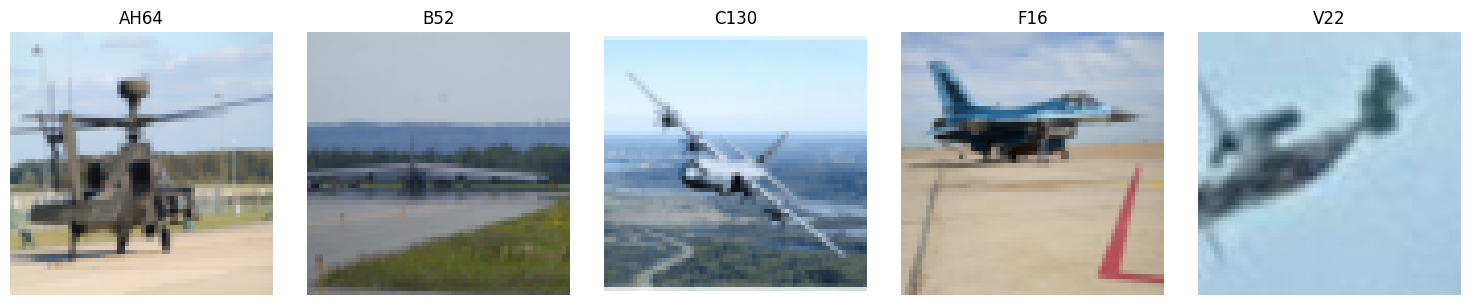

In [14]:

import os
import zipfile
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

train3 = pd.read_csv('03_train.csv')
test3 = pd.read_csv('03_test_x.csv')

IMG_DIR = Path(os.environ.get(
    'AICE_IMG_DIR',
    str(Path.cwd() / 'aice07_images')
))

if not (IMG_DIR / '03_train').exists() or not (IMG_DIR / '03_test').exists():
    with zipfile.ZipFile('03_images.zip') as z:
        z.extractall(IMG_DIR)

train_paths = [
    IMG_DIR / '03_train' / row.label / row.file_name
    for row in train3.itertuples(index=False)
]

test_paths = [
    IMG_DIR / '03_test' / name
    for name in test3['file_name']
]

missing_train = sum(not p.is_file() for p in train_paths)
missing_test = sum(not p.is_file() for p in test_paths)

print('학습 CSV:', train3.shape)
print('테스트 CSV:', test3.shape)

print('\n클래스 분포:')
print(train3['label'].value_counts().sort_index())

print('\n이미지 파일 확인:')
print('학습 파일:', len(train_paths))
print('테스트 파일:', len(test_paths))
print('학습 누락:', missing_train)
print('테스트 누락:', missing_test)

assert missing_train == 0 and missing_test == 0

image_info = Counter()

for path in train_paths + test_paths:
    with Image.open(path) as img:
        image_info[(img.size, img.mode)] += 1

print('\n이미지 크기 및 채널:')
for key, count in image_info.items():
    print(key, ':', count, '장')

print('\n학습 데이터 미리보기:')
display(train3.head(5))

print('\n테스트 데이터 미리보기:')
display(test3.head(3))

classes3 = sorted(train3['label'].unique())

fig, axes = plt.subplots(1, len(classes3), figsize=(15, 3))

for ax, label in zip(axes, classes3):
    sample = train3.loc[train3['label'] == label].iloc[0]
    path = IMG_DIR / '03_train' / label / sample['file_name']

    with Image.open(path) as img:
        ax.imshow(img.convert('RGB'))

    ax.set_title(label)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [15]:

import numpy as np
from sklearn.model_selection import train_test_split
from PIL import Image

SIZE3 = 64
CLASSES3 = sorted(train3['label'].unique())
class_to_idx3 = {name: i for i, name in enumerate(CLASSES3)}

def load_images3(paths):
    images = []

    for path in paths:
        with Image.open(path) as img:
            arr = np.asarray(
                img.convert('RGB'),
                dtype=np.float32
            ) / 255.0
            images.append(arr)

    return np.stack(images)

X3_all = load_images3(train_paths)
X3_test = load_images3(test_paths)

y3_all = train3['label'].map(class_to_idx3).to_numpy()

idx_train3, idx_valid3 = train_test_split(
    np.arange(len(y3_all)),
    test_size=0.2,
    random_state=42,
    stratify=y3_all
)

X3_train = X3_all[idx_train3]
X3_valid = X3_all[idx_valid3]

y3_train = y3_all[idx_train3]
y3_valid = y3_all[idx_valid3]

print('학습 이미지:', X3_train.shape)
print('검증 이미지:', X3_valid.shape)
print('테스트 이미지:', X3_test.shape)

print('\n데이터 타입:', X3_train.dtype)
print('학습 픽셀 범위:', X3_train.min(), X3_train.max())
print('검증 픽셀 범위:', X3_valid.min(), X3_valid.max())
print('테스트 픽셀 범위:', X3_test.min(), X3_test.max())

print('\n클래스 번호:')
print(class_to_idx3)

print('\n클래스별 학습·검증 분포:')
print(pd.DataFrame({
    '클래스': CLASSES3,
    '학습': np.bincount(y3_train, minlength=len(CLASSES3)),
    '검증': np.bincount(y3_valid, minlength=len(CLASSES3))
}))

assert X3_train.shape == (960, 64, 64, 3)
assert X3_valid.shape == (240, 64, 64, 3)
assert X3_test.shape == (300, 64, 64, 3)

assert np.isfinite(X3_train).all()
assert np.isfinite(X3_valid).all()
assert np.isfinite(X3_test).all()

assert all(
    arr.min() >= 0 and arr.max() <= 1
    for arr in [X3_train, X3_valid, X3_test]
)

print('\n이미지 전처리 및 데이터 분리 검증: 통과')


학습 이미지: (960, 64, 64, 3)
검증 이미지: (240, 64, 64, 3)
테스트 이미지: (300, 64, 64, 3)

데이터 타입: float32
학습 픽셀 범위: 0.0 1.0
검증 픽셀 범위: 0.0 1.0
테스트 픽셀 범위: 0.0 1.0

클래스 번호:
{'AH64': 0, 'B52': 1, 'C130': 2, 'F16': 3, 'V22': 4}

클래스별 학습·검증 분포:
    클래스   학습  검증
0  AH64  192  48
1   B52  192  48
2  C130  192  48
3   F16  192  48
4   V22  192  48

이미지 전처리 및 데이터 분리 검증: 통과


In [16]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

model3 = Sequential([
    Input(shape=(64, 64, 3)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(len(CLASSES3), activation='softmax')
])

model3.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model3.summary()

print('\n입력 형태:', model3.input_shape)
print('출력 형태:', model3.output_shape)
print('전체 파라미터:', model3.count_params())
print('클래스:', CLASSES3)

assert model3.input_shape == (None, 64, 64, 3)
assert model3.output_shape == (None, 5)

print('\nCNN 모델 구성 검증: 통과')


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,413 (974.27 KB)

 Trainable params: 249,413 (974.27 KB)

 Non-trainable params: 0 (0.00 B)


입력 형태: (None, 64, 64, 3)
출력 형태: (None, 5)
전체 파라미터: 249413
클래스: ['AH64', 'B52', 'C130', 'F16', 'V22']

CNN 모델 구성 검증: 통과


In [17]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
from sklearn.metrics import classification_report

augment3 = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

train_gen3 = augment3.flow(
    X3_train,
    y3_train,
    batch_size=32,
    shuffle=True,
    seed=42
)

version3 = 1
while os.path.exists(f'candidate_3_v{version3}.h5'):
    version3 += 1

best_path3 = f'candidate_3_v{version3}.h5'

callbacks3 = [
    ModelCheckpoint(
        filepath=best_path3,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=16,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        mode='min',
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1
    )
]

history3 = model3.fit(
    train_gen3,
    validation_data=(X3_valid, y3_valid),
    epochs=60,
    callbacks=callbacks3,
    verbose=1
)

best_epoch3 = np.argmax(history3.history['val_accuracy']) + 1

best_model3 = tf.keras.models.load_model(best_path3)

train_loss3, train_acc3 = best_model3.evaluate(
    X3_train, y3_train, verbose=0
)

valid_loss3, valid_acc3 = best_model3.evaluate(
    X3_valid, y3_valid, verbose=0
)

valid_pred3 = np.argmax(
    best_model3.predict(X3_valid, verbose=0),
    axis=1
)

print('\n실제 학습 Epoch:', len(history3.history['loss']))
print('최고 검증 정확도 Epoch:', best_epoch3)
print('최고 모델 파일:', best_path3)

print('\n저장 모델 평가:')
print(f'학습 정확도: {train_acc3:.4f}')
print(f'검증 정확도: {valid_acc3:.4f}')
print(f'검증 손실: {valid_loss3:.4f}')

print('\n클래스별 검증 성능:')
print(classification_report(
    y3_valid,
    valid_pred3,
    target_names=CLASSES3,
    zero_division=0
))

print('\n검증 예측 클래스 분포:')
for i, name in enumerate(CLASSES3):
    print(name, ':', int(np.sum(valid_pred3 == i)))

assert os.path.exists(best_path3)

assert np.isclose(
    valid_acc3,
    max(history3.history['val_accuracy']),
    atol=1e-4
)

print('\n최고 체크포인트 저장 및 검증: 통과')


Epoch 1/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step - accuracy: 0.1861 - loss: 1.6136
Epoch 1: val_accuracy improved from None to 0.20000, saving model to candidate_3_v1.h5



Epoch 1: finished saving model to candidate_3_v1.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 26s 721ms/step - accuracy: 0.1969 - loss: 1.6126 - val_accuracy: 0.2000 - val_loss: 1.6096 - learning_rate: 3.0000e-04
Epoch 2/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 599ms/step - accuracy: 0.2179 - loss: 1.6095
Epoch 2: val_accuracy did not improve from 0.20000
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 644ms/step - accuracy: 0.1990 - loss: 1.6101 - val_accuracy: 0.1792 - val_loss: 1.6095 - learning_rate: 3.0000e-04
Epoch 3/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.2466 - loss: 1.6083
Epoch 3: val_accuracy did not improve from 0.20000
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 643ms/step - accuracy: 0.2167 - loss: 1.6092 - val_accuracy: 0.1875 - val_loss: 1.6096 - learning_rate: 3.0000e-04
Epoch 4/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 644ms/step - accuracy: 0.1913 - loss: 1.6096
Epoch 4: val_accuracy did not improve from 0.20000
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 680ms/step - accuracy: 0.2000 - loss: 1.6095 - val_accuracy: 0.1875


Epoch 5: finished saving model to candidate_3_v1.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 640ms/step - accuracy: 0.1948 - loss: 1.6088 - val_accuracy: 0.2083 - val_loss: 1.6095 - learning_rate: 3.0000e-04
Epoch 6/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - accuracy: 0.1868 - loss: 1.6066
Epoch 6: val_accuracy did not improve from 0.20833
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 709ms/step - accuracy: 0.1958 - loss: 1.6067 - val_accuracy: 0.1750 - val_loss: 1.6076 - learning_rate: 3.0000e-04
Epoch 7/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 597ms/step - accuracy: 0.2093 - loss: 1.6053
Epoch 7: val_accuracy improved from 0.20833 to 0.22083, saving model to candidate_3_v1.h5



Epoch 7: finished saving model to candidate_3_v1.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 644ms/step - accuracy: 0.1948 - loss: 1.6069 - val_accuracy: 0.2208 - val_loss: 1.6070 - learning_rate: 3.0000e-04
Epoch 8/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 619ms/step - accuracy: 0.2083 - loss: 1.6045
Epoch 8: val_accuracy did not improve from 0.22083
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 685ms/step - accuracy: 0.2052 - loss: 1.6062 - val_accuracy: 0.2125 - val_loss: 1.6074 - learning_rate: 3.0000e-04
Epoch 9/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.2410 - loss: 1.6061
Epoch 9: val_accuracy did not improve from 0.22083
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 637ms/step - accuracy: 0.2292 - loss: 1.6062 - val_accuracy: 0.2083 - val_loss: 1.6056 - learning_rate: 3.0000e-04
Epoch 10/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 601ms/step - accuracy: 0.2262 - loss: 1.6023
Epoch 10: val_accuracy did not improve from 0.22083
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 646ms/step - accuracy: 0.2146 - loss: 1.6060 - val_accuracy: 0.21


Epoch 12: finished saving model to candidate_3_v1.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 635ms/step - accuracy: 0.2344 - loss: 1.6001 - val_accuracy: 0.2333 - val_loss: 1.6069 - learning_rate: 3.0000e-04
Epoch 13/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.2502 - loss: 1.5969
Epoch 13: val_accuracy did not improve from 0.23333
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 646ms/step - accuracy: 0.2302 - loss: 1.5989 - val_accuracy: 0.1958 - val_loss: 1.6078 - learning_rate: 3.0000e-04
Epoch 14/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - accuracy: 0.2173 - loss: 1.6005
Epoch 14: val_accuracy did not improve from 0.23333
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 667ms/step - accuracy: 0.2240 - loss: 1.6014 - val_accuracy: 0.1958 - val_loss: 1.6094 - learning_rate: 3.0000e-04
Epoch 15/60
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 600ms/step - accuracy: 0.2062 - loss: 1.5991
Epoch 15: val_accuracy did not improve from 0.23333

Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
30/30 ━━━━━━━


실제 학습 Epoch: 28
최고 검증 정확도 Epoch: 12
최고 모델 파일: candidate_3_v1.h5

저장 모델 평가:
학습 정확도: 0.2438
검증 정확도: 0.2333
검증 손실: 1.6069

클래스별 검증 성능:
              precision    recall  f1-score   support

        AH64       0.30      0.21      0.25        48
         B52       0.19      0.17      0.18        48
        C130       0.00      0.00      0.00        48
         F16       0.23      0.40      0.29        48
         V22       0.23      0.40      0.29        48

    accuracy                           0.23       240
   macro avg       0.19      0.23      0.20       240
weighted avg       0.19      0.23      0.20       240


검증 예측 클래스 분포:
AH64 : 33
B52 : 43
C130 : 1
F16 : 81
V22 : 82

최고 체크포인트 저장 및 검증: 통과


In [18]:

from tensorflow.keras.layers import Flatten
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)

model3_v2 = Sequential([
    Input(shape=(64, 64, 3)),

    Conv2D(32, 3, activation='relu', padding='same'),
    MaxPooling2D(2),

    Conv2D(64, 3, activation='relu', padding='same'),
    MaxPooling2D(2),

    Conv2D(128, 3, activation='relu', padding='same'),
    Conv2D(128, 3, activation='relu', padding='same'),
    MaxPooling2D(2),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')
])

model3_v2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

augment3_v2 = ImageDataGenerator(
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,
    fill_mode='nearest'
)

train_gen3_v2 = augment3_v2.flow(
    X3_train,
    y3_train,
    batch_size=32,
    shuffle=True,
    seed=42
)

version3_v2 = 2
while os.path.exists(f'candidate_3_v{version3_v2}.h5'):
    version3_v2 += 1

best_path3_v2 = f'candidate_3_v{version3_v2}.h5'

callbacks3_v2 = [
    ModelCheckpoint(
        best_path3_v2,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

print('개선 모델 파라미터:', model3_v2.count_params())

history3_v2 = model3_v2.fit(
    train_gen3_v2,
    validation_data=(X3_valid, y3_valid),
    epochs=45,
    callbacks=callbacks3_v2,
    verbose=1
)

best_model3_v2 = tf.keras.models.load_model(best_path3_v2)

train_loss_v2, train_acc_v2 = best_model3_v2.evaluate(
    X3_train, y3_train, verbose=0
)

valid_loss_v2, valid_acc_v2 = best_model3_v2.evaluate(
    X3_valid, y3_valid, verbose=0
)

valid_pred_v2 = np.argmax(
    best_model3_v2.predict(X3_valid, verbose=0),
    axis=1
)

print('\n기존 v1 검증 정확도: 0.2333')
print('개선 v2 학습 정확도:', round(train_acc_v2, 4))
print('개선 v2 검증 정확도:', round(valid_acc_v2, 4))
print('개선 v2 검증 손실:', round(valid_loss_v2, 4))

print('\n실제 학습 Epoch:', len(history3_v2.history['loss']))
print('최고 Epoch:', np.argmax(history3_v2.history['val_accuracy']) + 1)
print('저장 모델:', best_path3_v2)

print('\n클래스별 검증 성능:')
print(classification_report(
    y3_valid,
    valid_pred_v2,
    target_names=CLASSES3,
    zero_division=0
))

print('\n검증 예측 클래스 분포:')
for i, name in enumerate(CLASSES3):
    print(name, ':', int(np.sum(valid_pred_v2 == i)))

assert np.isclose(
    valid_acc_v2,
    max(history3_v2.history['val_accuracy']),
    atol=1e-4
)

print('\n개선 모델 체크포인트 검증: 통과')


개선 모델 파라미터: 765509
Epoch 1/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 773ms/step - accuracy: 0.2019 - loss: 1.6228
Epoch 1: val_accuracy improved from None to 0.20000, saving model to candidate_3_v2.h5



Epoch 1: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 35s 877ms/step - accuracy: 0.1979 - loss: 1.6165 - val_accuracy: 0.2000 - val_loss: 1.6095 - learning_rate: 0.0010
Epoch 2/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.2172 - loss: 1.6092
Epoch 2: val_accuracy did not improve from 0.20000
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 649ms/step - accuracy: 0.2062 - loss: 1.6096 - val_accuracy: 0.2000 - val_loss: 1.6094 - learning_rate: 0.0010
Epoch 3/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 623ms/step - accuracy: 0.1933 - loss: 1.6099
Epoch 3: val_accuracy did not improve from 0.20000
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 690ms/step - accuracy: 0.1833 - loss: 1.6099 - val_accuracy: 0.1792 - val_loss: 1.6095 - learning_rate: 0.0010
Epoch 4/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 647ms/step - accuracy: 0.1985 - loss: 1.6094
Epoch 4: val_accuracy did not improve from 0.20000
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 684ms/step - accuracy: 0.2000 - loss: 1.6096 - val_accuracy: 0.2000 - val_loss:


Epoch 9: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 644ms/step - accuracy: 0.2094 - loss: 1.6107 - val_accuracy: 0.2042 - val_loss: 1.6094 - learning_rate: 5.0000e-04
Epoch 10/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.2185 - loss: 1.6090
Epoch 10: val_accuracy did not improve from 0.20417
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 647ms/step - accuracy: 0.1990 - loss: 1.6096 - val_accuracy: 0.2000 - val_loss: 1.6091 - learning_rate: 5.0000e-04
Epoch 11/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 612ms/step - accuracy: 0.2288 - loss: 1.6087
Epoch 11: val_accuracy did not improve from 0.20417
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 656ms/step - accuracy: 0.2021 - loss: 1.6093 - val_accuracy: 0.2000 - val_loss: 1.6091 - learning_rate: 5.0000e-04
Epoch 12/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.2123 - loss: 1.6077
Epoch 12: val_accuracy improved from 0.20417 to 0.21250, saving model to candidate_3_v2.h5



Epoch 12: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 639ms/step - accuracy: 0.2083 - loss: 1.6082 - val_accuracy: 0.2125 - val_loss: 1.6077 - learning_rate: 5.0000e-04
Epoch 13/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 666ms/step - accuracy: 0.2343 - loss: 1.6074
Epoch 13: val_accuracy improved from 0.21250 to 0.23750, saving model to candidate_3_v2.h5



Epoch 13: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 713ms/step - accuracy: 0.2260 - loss: 1.6085 - val_accuracy: 0.2375 - val_loss: 1.6083 - learning_rate: 5.0000e-04
Epoch 14/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.2382 - loss: 1.6054
Epoch 14: val_accuracy did not improve from 0.23750
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 649ms/step - accuracy: 0.2260 - loss: 1.6071 - val_accuracy: 0.2333 - val_loss: 1.6091 - learning_rate: 5.0000e-04
Epoch 15/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 611ms/step - accuracy: 0.2407 - loss: 1.6009
Epoch 15: val_accuracy did not improve from 0.23750
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 701ms/step - accuracy: 0.2344 - loss: 1.6057 - val_accuracy: 0.2250 - val_loss: 1.6073 - learning_rate: 5.0000e-04
Epoch 16/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.2205 - loss: 1.6054
Epoch 16: val_accuracy did not improve from 0.23750
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 649ms/step - accuracy: 0.2333 - loss: 1.6069 - val_accuracy:


Epoch 17: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 653ms/step - accuracy: 0.2313 - loss: 1.6056 - val_accuracy: 0.2417 - val_loss: 1.6055 - learning_rate: 5.0000e-04
Epoch 18/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 660ms/step - accuracy: 0.2184 - loss: 1.6073
Epoch 18: val_accuracy did not improve from 0.24167
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 705ms/step - accuracy: 0.2146 - loss: 1.6079 - val_accuracy: 0.2167 - val_loss: 1.6032 - learning_rate: 5.0000e-04
Epoch 19/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.2717 - loss: 1.6023
Epoch 19: val_accuracy did not improve from 0.24167
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 649ms/step - accuracy: 0.2562 - loss: 1.6044 - val_accuracy: 0.2208 - val_loss: 1.6017 - learning_rate: 5.0000e-04
Epoch 20/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 639ms/step - accuracy: 0.2241 - loss: 1.5954
Epoch 20: val_accuracy improved from 0.24167 to 0.25417, saving model to candidate_3_v2.h5


... (9 outputs left out)


Epoch 42: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 706ms/step - accuracy: 0.4000 - loss: 1.3580 - val_accuracy: 0.3542 - val_loss: 1.5054 - learning_rate: 5.0000e-04
Epoch 43/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - accuracy: 0.4012 - loss: 1.3616
Epoch 43: val_accuracy improved from 0.35417 to 0.36667, saving model to candidate_3_v2.h5



Epoch 43: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 651ms/step - accuracy: 0.4187 - loss: 1.3399 - val_accuracy: 0.3667 - val_loss: 1.4518 - learning_rate: 5.0000e-04
Epoch 44/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 605ms/step - accuracy: 0.4315 - loss: 1.3222
Epoch 44: val_accuracy did not improve from 0.36667
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 650ms/step - accuracy: 0.4281 - loss: 1.3283 - val_accuracy: 0.3542 - val_loss: 1.4638 - learning_rate: 5.0000e-04
Epoch 45/45
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 618ms/step - accuracy: 0.4395 - loss: 1.3246
Epoch 45: val_accuracy improved from 0.36667 to 0.38333, saving model to candidate_3_v2.h5



Epoch 45: finished saving model to candidate_3_v2.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 666ms/step - accuracy: 0.4417 - loss: 1.3224 - val_accuracy: 0.3833 - val_loss: 1.4626 - learning_rate: 5.0000e-04
Restoring model weights from the end of the best epoch: 45.



기존 v1 검증 정확도: 0.2333
개선 v2 학습 정확도: 0.5448
개선 v2 검증 정확도: 0.3833
개선 v2 검증 손실: 1.4626

실제 학습 Epoch: 45
최고 Epoch: 45
저장 모델: candidate_3_v2.h5

클래스별 검증 성능:
              precision    recall  f1-score   support

        AH64       0.42      0.65      0.51        48
         B52       0.36      0.50      0.42        48
        C130       0.38      0.12      0.19        48
         F16       0.34      0.25      0.29        48
         V22       0.40      0.40      0.40        48

    accuracy                           0.38       240
   macro avg       0.38      0.38      0.36       240
weighted avg       0.38      0.38      0.36       240


검증 예측 클래스 분포:
AH64 : 74
B52 : 67
C130 : 16
F16 : 35
V22 : 48

개선 모델 체크포인트 검증: 통과


In [19]:

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)

base_path3 = 'candidate_3_v2.h5'
assert os.path.exists(base_path3)

model3_v3 = tf.keras.models.load_model(
    base_path3,
    compile=False
)

model3_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

augment3_v3 = ImageDataGenerator(
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True,
    fill_mode='nearest'
)

train_gen3_v3 = augment3_v3.flow(
    X3_train,
    y3_train,
    batch_size=32,
    shuffle=True,
    seed=42
)

version3_v3 = 3
while os.path.exists(f'candidate_3_v{version3_v3}.h5'):
    version3_v3 += 1

best_path3_v3 = f'candidate_3_v{version3_v3}.h5'

callbacks3_v3 = [
    ModelCheckpoint(
        best_path3_v3,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=14,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        mode='min',
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1
    )
]

history3_v3 = model3_v3.fit(
    train_gen3_v3,
    validation_data=(X3_valid, y3_valid),
    epochs=40,
    callbacks=callbacks3_v3,
    verbose=1
)

best_model3_v3 = tf.keras.models.load_model(best_path3_v3)

train_loss_v3, train_acc_v3 = best_model3_v3.evaluate(
    X3_train, y3_train, verbose=0
)

valid_loss_v3, valid_acc_v3 = best_model3_v3.evaluate(
    X3_valid, y3_valid, verbose=0
)

valid_pred_v3 = np.argmax(
    best_model3_v3.predict(X3_valid, verbose=0),
    axis=1
)

v2_model_check = tf.keras.models.load_model(
    base_path3, compile=False
)
v2_pred_check = np.argmax(
    v2_model_check.predict(X3_valid, verbose=0),
    axis=1
)
v2_acc_check = np.mean(v2_pred_check == y3_valid)

print('\n모델별 검증 정확도:')
print('v1:', 0.2333)
print('v2:', round(v2_acc_check, 4))
print('v3:', round(valid_acc_v3, 4))

print('\nv3 저장 모델 평가:')
print('학습 정확도:', round(train_acc_v3, 4))
print('검증 정확도:', round(valid_acc_v3, 4))
print('검증 손실:', round(valid_loss_v3, 4))

print('\n추가 학습 Epoch:', len(history3_v3.history['loss']))
print('최고 Epoch:', np.argmax(history3_v3.history['val_accuracy']) + 1)
print('저장 모델:', best_path3_v3)

print('\n클래스별 검증 성능:')
print(classification_report(
    y3_valid,
    valid_pred_v3,
    target_names=CLASSES3,
    zero_division=0
))

print('\n검증 예측 클래스 분포:')
for i, name in enumerate(CLASSES3):
    print(name, ':', int(np.sum(valid_pred_v3 == i)))

assert np.isclose(
    valid_acc_v3,
    max(history3_v3.history['val_accuracy']),
    atol=1e-4
)

print('\n체크포인트 검증: 통과')


Epoch 1/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 738ms/step - accuracy: 0.4720 - loss: 1.2497
Epoch 1: val_accuracy improved from None to 0.39167, saving model to candidate_3_v3.h5



Epoch 1: finished saving model to candidate_3_v3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 794ms/step - accuracy: 0.4708 - loss: 1.2550 - val_accuracy: 0.3917 - val_loss: 1.4689 - learning_rate: 3.0000e-04
Epoch 2/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 601ms/step - accuracy: 0.4814 - loss: 1.2758
Epoch 2: val_accuracy did not improve from 0.39167
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 638ms/step - accuracy: 0.4719 - loss: 1.2801 - val_accuracy: 0.3833 - val_loss: 1.4464 - learning_rate: 3.0000e-04
Epoch 3/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 665ms/step - accuracy: 0.4719 - loss: 1.2644
Epoch 3: val_accuracy did not improve from 0.39167
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 710ms/step - accuracy: 0.4802 - loss: 1.2537 - val_accuracy: 0.3667 - val_loss: 1.4572 - learning_rate: 3.0000e-04
Epoch 4/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.4967 - loss: 1.1996
Epoch 4: val_accuracy did not improve from 0.39167
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 638ms/step - accuracy: 0.4760 - loss: 1.2469 - val_accuracy: 0.3708


Epoch 11: finished saving model to candidate_3_v3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 640ms/step - accuracy: 0.5188 - loss: 1.1938 - val_accuracy: 0.3958 - val_loss: 1.4602 - learning_rate: 1.5000e-04
Epoch 12/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.5201 - loss: 1.1606
Epoch 12: val_accuracy did not improve from 0.39583
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 641ms/step - accuracy: 0.5354 - loss: 1.1570 - val_accuracy: 0.3708 - val_loss: 1.4797 - learning_rate: 1.5000e-04
Epoch 13/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 664ms/step - accuracy: 0.5257 - loss: 1.1402
Epoch 13: val_accuracy did not improve from 0.39583
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 709ms/step - accuracy: 0.5042 - loss: 1.1790 - val_accuracy: 0.3750 - val_loss: 1.4719 - learning_rate: 1.5000e-04
Epoch 14/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - accuracy: 0.5224 - loss: 1.1379
Epoch 14: val_accuracy did not improve from 0.39583

Epoch 14: ReduceLROnPlateau reducing learning rate to 7.500000356230885e-05.
30/30 ━━━━━━━


Epoch 19: finished saving model to candidate_3_v3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 654ms/step - accuracy: 0.4979 - loss: 1.1556 - val_accuracy: 0.4083 - val_loss: 1.4888 - learning_rate: 7.5000e-05
Epoch 20/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 621ms/step - accuracy: 0.5424 - loss: 1.1663
Epoch 20: val_accuracy did not improve from 0.40833

Epoch 20: ReduceLROnPlateau reducing learning rate to 3.7500001781154424e-05.
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 688ms/step - accuracy: 0.5271 - loss: 1.1743 - val_accuracy: 0.3917 - val_loss: 1.4903 - learning_rate: 7.5000e-05
Epoch 21/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 605ms/step - accuracy: 0.5600 - loss: 1.0905
Epoch 21: val_accuracy did not improve from 0.40833
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 649ms/step - accuracy: 0.5427 - loss: 1.1249 - val_accuracy: 0.4042 - val_loss: 1.4894 - learning_rate: 3.7500e-05
Epoch 22/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - accuracy: 0.5530 - loss: 1.1200
Epoch 22: val_accuracy improved from 0.40833 to 0.41250, saving 


Epoch 22: finished saving model to candidate_3_v3.h5
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 651ms/step - accuracy: 0.5615 - loss: 1.1135 - val_accuracy: 0.4125 - val_loss: 1.4950 - learning_rate: 3.7500e-05
Epoch 23/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 662ms/step - accuracy: 0.5184 - loss: 1.1320
Epoch 23: val_accuracy did not improve from 0.41250
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 707ms/step - accuracy: 0.5312 - loss: 1.1135 - val_accuracy: 0.4000 - val_loss: 1.4982 - learning_rate: 3.7500e-05
Epoch 24/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.5600 - loss: 1.0847
Epoch 24: val_accuracy did not improve from 0.41250
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 638ms/step - accuracy: 0.5406 - loss: 1.1117 - val_accuracy: 0.4000 - val_loss: 1.4917 - learning_rate: 3.7500e-05
Epoch 25/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 614ms/step - accuracy: 0.5516 - loss: 1.0860
Epoch 25: val_accuracy did not improve from 0.41250
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 683ms/step - accuracy: 0.5437 - loss: 1.1035 - val_accuracy:


모델별 검증 정확도:
v1: 0.2333
v2: 0.3833
v3: 0.4125

v3 저장 모델 평가:
학습 정확도: 0.6562
검증 정확도: 0.4125
검증 손실: 1.495

추가 학습 Epoch: 36
최고 Epoch: 22
저장 모델: candidate_3_v3.h5

클래스별 검증 성능:
              precision    recall  f1-score   support

        AH64       0.49      0.58      0.53        48
         B52       0.42      0.54      0.47        48
        C130       0.21      0.10      0.14        48
         F16       0.41      0.35      0.38        48
         V22       0.41      0.48      0.44        48

    accuracy                           0.41       240
   macro avg       0.39      0.41      0.39       240
weighted avg       0.39      0.41      0.39       240


검증 예측 클래스 분포:
AH64 : 57
B52 : 62
C130 : 24
F16 : 41
V22 : 56

체크포인트 검증: 통과


In [20]:

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report

tta_model3 = tf.keras.models.load_model(
    'candidate_3_v3.h5',
    compile=False
)

prob_original3 = tta_model3.predict(
    X3_valid, batch_size=32, verbose=0
)

prob_flip3 = tta_model3.predict(
    np.flip(X3_valid, axis=2).copy(),
    batch_size=32,
    verbose=0
)

pred_original3 = np.argmax(prob_original3, axis=1)

prob_tta3 = (prob_original3 + prob_flip3) / 2
pred_tta3 = np.argmax(prob_tta3, axis=1)

acc_original3 = accuracy_score(y3_valid, pred_original3)
acc_tta3 = accuracy_score(y3_valid, pred_tta3)

results_tta3 = pd.DataFrame({
    '방법': ['v3 원본 예측', 'v3 좌우 반전 TTA'],
    '정답 수': [
        np.sum(pred_original3 == y3_valid),
        np.sum(pred_tta3 == y3_valid)
    ],
    '검증 정확도': [
        acc_original3,
        acc_tta3
    ]
})

display(results_tta3.round(4))

print('\nTTA 적용 후 클래스별 성능:')
print(classification_report(
    y3_valid,
    pred_tta3,
    target_names=CLASSES3,
    zero_division=0
))

print('\nTTA 예측 클래스 분포:')
for i, name in enumerate(CLASSES3):
    print(name, ':', int(np.sum(pred_tta3 == i)))

assert np.isclose(acc_original3, 0.4125, atol=1e-4)

print('\n기존 체크포인트 재현 검증: 통과')


,방법,정답 수,검증 정확도
0,v3 원본 예측,99,0.4125
1,v3 좌우 반전 TTA,100,0.4167



TTA 적용 후 클래스별 성능:
              precision    recall  f1-score   support

        AH64       0.49      0.58      0.53        48
         B52       0.44      0.56      0.50        48
        C130       0.18      0.08      0.11        48
         F16       0.44      0.40      0.42        48
         V22       0.39      0.46      0.42        48

    accuracy                           0.42       240
   macro avg       0.39      0.42      0.40       240
weighted avg       0.39      0.42      0.40       240


TTA 예측 클래스 분포:
AH64 : 57
B52 : 61
C130 : 22
F16 : 43
V22 : 57

기존 체크포인트 재현 검증: 통과


In [21]:

import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report

def extract_hog3(img, cell=12, bins=9):
    arr = np.asarray(img, dtype=np.float32)

    gx = np.zeros_like(arr)
    gy = np.zeros_like(arr)

    gx[:, 1:-1, :] = arr[:, 2:, :] - arr[:, :-2, :]
    gy[1:-1, :, :] = arr[2:, :, :] - arr[:-2, :, :]

    magnitude = np.sqrt(gx**2 + gy**2)
    channel = np.argmax(magnitude, axis=2)[:, :, None]

    mag = np.take_along_axis(magnitude, channel, axis=2)[:, :, 0]
    dx = np.take_along_axis(gx, channel, axis=2)[:, :, 0]
    dy = np.take_along_axis(gy, channel, axis=2)[:, :, 0]

    angles = np.mod(np.degrees(np.arctan2(dy, dx)), 180)

    nr = arr.shape[0] // cell
    nc = arr.shape[1] // cell
    histograms = np.zeros((nr, nc, bins), dtype=np.float32)

    for i in range(nr):
        for j in range(nc):
            a = angles[i*cell:(i+1)*cell, j*cell:(j+1)*cell].ravel()
            m = mag[i*cell:(i+1)*cell, j*cell:(j+1)*cell].ravel()

            histograms[i, j] = np.histogram(
                a, bins=bins, range=(0, 180), weights=m
            )[0]

    blocks = []

    for i in range(nr - 1):
        for j in range(nc - 1):
            block = histograms[i:i+2, j:j+2].ravel()
            block = block / np.sqrt(np.sum(block**2) + 1e-5)
            block = np.clip(block, 0, 0.2)
            block = block / np.sqrt(np.sum(block**2) + 1e-5)
            blocks.append(block)

    return np.concatenate(blocks)

cv_hog3 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

hog_results3 = []
hog_models3 = {}
hog_features3 = {}

for cell in [8, 12, 16]:
    X_hog_train = np.stack([
        extract_hog3(img, cell) for img in X3_train
    ])

    X_hog_valid = np.stack([
        extract_hog3(img, cell) for img in X3_valid
    ])

    pipe = make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=3, gamma='scale')
    )

    scores = cross_val_score(
        pipe,
        X_hog_train,
        y3_train,
        cv=cv_hog3,
        scoring='accuracy',
        n_jobs=1
    )

    pipe.fit(X_hog_train, y3_train)
    pred = pipe.predict(X_hog_valid)

    hog_results3.append({
        '셀 크기': cell,
        '특징 수': X_hog_train.shape[1],
        'CV 평균 정확도': scores.mean(),
        '검증 정확도': accuracy_score(y3_valid, pred),
        '검증 Macro F1': f1_score(
            y3_valid, pred, average='macro'
        )
    })

    hog_models3[cell] = pipe
    hog_features3[cell] = (X_hog_train, X_hog_valid)

comparison_hog3 = pd.DataFrame(hog_results3).sort_values(
    'CV 평균 정확도',
    ascending=False
)

display(comparison_hog3.round(4))

best_cell3 = int(comparison_hog3.iloc[0]['셀 크기'])
best_hog_model3 = hog_models3[best_cell3]
best_hog_valid3 = hog_features3[best_cell3][1]

best_hog_pred3 = best_hog_model3.predict(best_hog_valid3)

print('\nCV 기준 최고 셀 크기:', best_cell3)

print('\n클래스별 검증 성능:')
print(classification_report(
    y3_valid,
    best_hog_pred3,
    target_names=CLASSES3,
    zero_division=0
))

print('\n기존 CNN v3 TTA 정확도: 0.4167')
print('HOG 검증 정확도:', round(
    accuracy_score(y3_valid, best_hog_pred3), 4
))

print('\nHOG 비교 실험 완료')


,셀 크기,특징 수,CV 평균 정확도,검증 정확도,검증 Macro F1
1,12,576,0.5031,0.5000,0.4958
0,8,1764,0.4667,0.4458,0.4447
2,16,324,0.4448,0.4667,0.4635



CV 기준 최고 셀 크기: 12

클래스별 검증 성능:
              precision    recall  f1-score   support

        AH64       0.49      0.69      0.57        48
         B52       0.57      0.52      0.54        48
        C130       0.40      0.35      0.37        48
         F16       0.48      0.42      0.44        48
         V22       0.57      0.52      0.54        48

    accuracy                           0.50       240
   macro avg       0.50      0.50      0.50       240
weighted avg       0.50      0.50      0.50       240


기존 CNN v3 TTA 정확도: 0.4167
HOG 검증 정확도: 0.5

HOG 비교 실험 완료


In [22]:

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, Dense, Dropout
)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
)
from sklearn.metrics import classification_report

tf.keras.utils.set_random_seed(42)

train_df4 = train3.iloc[idx_train3].copy()
valid_df4 = train3.iloc[idx_valid3].copy()

for df in [train_df4, valid_df4]:
    df['path'] = [
        str(IMG_DIR / '03_train' / row.label / row.file_name)
        for row in df.itertuples(index=False)
    ]

train_gen4 = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True
).flow_from_dataframe(
    train_df4,
    x_col='path',
    y_col='label',
    classes=CLASSES3,
    class_mode='sparse',
    target_size=(224, 224),
    batch_size=32,
    shuffle=True,
    seed=42
)

valid_gen4 = ImageDataGenerator(
    preprocessing_function=preprocess_input
).flow_from_dataframe(
    valid_df4,
    x_col='path',
    y_col='label',
    classes=CLASSES3,
    class_mode='sparse',
    target_size=(224, 224),
    batch_size=32,
    shuffle=False
)

base4 = MobileNet(
    weights='imagenet',
    include_top=False,
    alpha=0.25,
    input_shape=(224, 224, 3)
)

base4.trainable = False

model3_v4 = Sequential([
    Input(shape=(224, 224, 3)),
    base4,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')
])

model3_v4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

version4 = 4
while os.path.exists(f'candidate_3_v{version4}.h5'):
    version4 += 1

best_path4 = f'candidate_3_v{version4}.h5'

callbacks4 = [
    ModelCheckpoint(
        best_path4,
        monitor='val_accuracy',
        mode='max',
        save_best_only=True,
        verbose=0
    ),
    EarlyStopping(
        monitor='val_accuracy',
        mode='max',
        patience=7,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6
    )
]

history4 = model3_v4.fit(
    train_gen4,
    validation_data=valid_gen4,
    epochs=25,
    callbacks=callbacks4,
    verbose=1
)

best_model4 = tf.keras.models.load_model(best_path4)

train_eval_gen4 = ImageDataGenerator(
    preprocessing_function=preprocess_input
).flow_from_dataframe(
    train_df4,
    x_col='path',
    y_col='label',
    classes=CLASSES3,
    class_mode='sparse',
    target_size=(224, 224),
    batch_size=32,
    shuffle=False
)

train_loss4, train_acc4 = best_model4.evaluate(
    train_eval_gen4, verbose=0
)

valid_loss4, valid_acc4 = best_model4.evaluate(
    valid_gen4, verbose=0
)

pred4 = np.argmax(
    best_model4.predict(valid_gen4, verbose=0),
    axis=1
)

print('\nMobileNet v1 평가:')
print('학습 정확도:', round(train_acc4, 4))
print('검증 정확도:', round(valid_acc4, 4))
print('검증 손실:', round(valid_loss4, 4))
print('학습 Epoch:', len(history4.history['loss']))
print('최고 Epoch:', np.argmax(history4.history['val_accuracy']) + 1)
print('저장 파일:', best_path4)

print('\n클래스별 검증 성능:')
print(classification_report(
    y3_valid,
    pred4,
    target_names=CLASSES3,
    zero_division=0
))

assert np.isclose(
    valid_acc4,
    max(history4.history['val_accuracy']),
    atol=1e-4
)

print('\nMobileNet 체크포인트 검증: 통과')


Found 960 validated image filenames belonging to 5 classes.
Found 240 validated image filenames belonging to 5 classes.
2108140/2108140 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 874ms/step - accuracy: 0.2173 - loss: 2.0332

30/30 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.2406 - loss: 1.8424 - val_accuracy: 0.3125 - val_loss: 1.5624 - learning_rate: 0.0010
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 920ms/step - accuracy: 0.3571 - loss: 1.4870

30/30 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.3667 - loss: 1.4573 - val_accuracy: 0.4208 - val_loss: 1.4106 - learning_rate: 0.0010
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 865ms/step - accuracy: 0.4142 - loss: 1.3763

30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 970ms/step - accuracy: 0.4302 - loss: 1.3638 - val_accuracy: 0.4625 - val_loss: 1.3400 - learning_rate: 0.0010
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 864ms/step - accuracy: 0.5192 - loss: 1.2395

30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 968ms/step - accuracy: 0.4812 - loss: 1.2673 - val_accuracy: 0.4708 - val_loss: 1.2851 - learning_rate: 0.0010
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 873ms/step - accuracy: 0.4926 - loss: 1.2564

30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 979ms/step - accuracy: 0.4948 - loss: 1.2388 - val_accuracy: 0.5292 - val_loss: 1.2268 - learning_rate: 0.0010
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 934ms/step - accuracy: 0.5417 - loss: 1.1348 - val_accuracy: 0.5125 - val_loss: 1.2003 - learning_rate: 0.0010
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 851ms/step - accuracy: 0.5648 - loss: 1.1034

... (3 outputs left out)

30/30 ━━━━━━━━━━━━━━━━━━━━ 41s 976ms/step - accuracy: 0.6219 - loss: 0.9336 - val_accuracy: 0.5917 - val_loss: 1.0378 - learning_rate: 0.0010
Epoch 13/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 964ms/step - accuracy: 0.6156 - loss: 0.9512 - val_accuracy: 0.5667 - val_loss: 1.0383 - learning_rate: 0.0010
Epoch 14/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 960ms/step - accuracy: 0.6438 - loss: 0.8918 - val_accuracy: 0.5708 - val_loss: 1.0323 - learning_rate: 0.0010
Epoch 15/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 972ms/step - accuracy: 0.6302 - loss: 0.9056 - val_accuracy: 0.5708 - val_loss: 1.0063 - learning_rate: 0.0010
Epoch 16/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 966ms/step - accuracy: 0.6531 - loss: 0.8751 - val_accuracy: 0.5917 - val_loss: 0.9930 - learning_rate: 0.0010
Epoch 17/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 974ms/step - accuracy: 0.6865 - loss: 0.8246 - val_accuracy: 0.5917 - val_loss: 1.0001 - learning_rate: 0.0010
Epoch 18/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 975ms/step - accuracy: 0.6802 - loss: 0.8222 

30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 978ms/step - accuracy: 0.6865 - loss: 0.8144 - val_accuracy: 0.6125 - val_loss: 0.9728 - learning_rate: 0.0010
Epoch 20/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 967ms/step - accuracy: 0.6885 - loss: 0.8086 - val_accuracy: 0.6083 - val_loss: 0.9957 - learning_rate: 0.0010
Epoch 21/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 974ms/step - accuracy: 0.7052 - loss: 0.7813 - val_accuracy: 0.5958 - val_loss: 0.9768 - learning_rate: 0.0010
Epoch 22/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 973ms/step - accuracy: 0.7031 - loss: 0.7732 - val_accuracy: 0.5792 - val_loss: 0.9800 - learning_rate: 0.0010
Epoch 23/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 963ms/step - accuracy: 0.7240 - loss: 0.7183 - val_accuracy: 0.6125 - val_loss: 0.9636 - learning_rate: 0.0010
Epoch 24/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 870ms/step - accuracy: 0.7196 - loss: 0.7065

30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 973ms/step - accuracy: 0.7208 - loss: 0.7195 - val_accuracy: 0.6250 - val_loss: 0.9331 - learning_rate: 0.0010
Epoch 25/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 976ms/step - accuracy: 0.7542 - loss: 0.6850 - val_accuracy: 0.6125 - val_loss: 0.9537 - learning_rate: 0.0010


Found 960 validated image filenames belonging to 5 classes.

MobileNet v1 평가:
학습 정확도: 0.8115
검증 정확도: 0.625
검증 손실: 0.9331
학습 Epoch: 25
최고 Epoch: 24
저장 파일: candidate_3_v4.h5

클래스별 검증 성능:
              precision    recall  f1-score   support

        AH64       0.76      0.71      0.73        48
         B52       0.62      0.65      0.63        48
        C130       0.46      0.52      0.49        48
         F16       0.69      0.60      0.64        48
         V22       0.63      0.65      0.64        48

    accuracy                           0.62       240
   macro avg       0.63      0.62      0.63       240
weighted avg       0.63      0.62      0.63       240


MobileNet 체크포인트 검증: 통과


In [23]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet import preprocess_input

model_path5 = 'candidate_3_v4.h5'
csv_path5 = 'candidate_3_v4.csv'

assert os.path.exists(model_path5)

loaded_model5 = tf.keras.models.load_model(
    model_path5,
    compile=False
)

test_df5 = test3.copy()
test_df5['path'] = [
    str(IMG_DIR / '03_test' / name)
    for name in test_df5['file_name']
]

assert test_df5['path'].map(os.path.isfile).all()

test_gen5 = ImageDataGenerator(
    preprocessing_function=preprocess_input
).flow_from_dataframe(
    test_df5,
    x_col='path',
    y_col=None,
    class_mode=None,
    target_size=(224, 224),
    batch_size=32,
    shuffle=False
)

assert [
    Path(p).name for p in test_gen5.filenames
] == test3['file_name'].tolist()

test_prob5 = loaded_model5.predict(
    test_gen5, verbose=0
)

test_idx5 = np.argmax(test_prob5, axis=1)
test_labels5 = np.array(CLASSES3)[test_idx5]

test_gen5.reset()

test_prob_check5 = loaded_model5.predict(
    test_gen5, verbose=0
)

assert np.array_equal(
    test_idx5,
    np.argmax(test_prob_check5, axis=1)
)

candidate5 = test3.copy()
candidate5['label'] = test_labels5

if os.path.exists(csv_path5):
    existing5 = pd.read_csv(csv_path5)
    pd.testing.assert_frame_equal(existing5, candidate5)
    print('기존 후보 CSV 일치:', csv_path5)
else:
    candidate5.to_csv(csv_path5, index=False)
    print('후보 CSV 생성:', csv_path5)

check5 = pd.read_csv(csv_path5)

assert check5.shape == (300, 2)
assert check5.columns.tolist() == ['file_name', 'label']
assert check5['file_name'].tolist() == test3['file_name'].tolist()
assert check5['label'].notna().all()
assert set(check5['label']).issubset(set(CLASSES3))
assert np.array_equal(check5['label'].to_numpy(), test_labels5)

print('\n모델 파일:', model_path5)
print('CSV 파일:', csv_path5)
print('CSV 행 수:', len(check5))
print('저장 모델 반복 예측 일치: True')
print('CSV 구조 및 행 순서 검증: 통과')

print('\n테스트 예측 분포:')
print(check5['label'].value_counts())

print('\n예측 CSV 미리보기:')
display(check5.head(5))


Found 300 validated image filenames.
후보 CSV 생성: candidate_3_v4.csv

모델 파일: candidate_3_v4.h5
CSV 파일: candidate_3_v4.csv
CSV 행 수: 300
저장 모델 반복 예측 일치: True
CSV 구조 및 행 순서 검증: 통과

테스트 예측 분포:
label
V22     75
C130    66
F16     64
B52     58
AH64    37
Name: count, dtype: int64

예측 CSV 미리보기:


,file_name,label
0,test_0001.png,B52
1,test_0002.png,AH64
2,test_0003.png,B52
3,test_0004.png,F16
4,test_0005.png,V22


In [24]:

import os
import shutil
import filecmp
import numpy as np
import pandas as pd
import tensorflow as tf

source_model3 = 'candidate_3_v4.h5'
source_csv3 = 'candidate_3_v4.csv'

target_model3 = 'answer_3.h5'
target_csv3 = 'answer_3.csv'

test_check3 = pd.read_csv('03_test_x.csv')
candidate_check3 = pd.read_csv(source_csv3)

assert candidate_check3.shape == (300, 2)
assert candidate_check3.columns.tolist() == ['file_name', 'label']

pd.testing.assert_frame_equal(
    candidate_check3[['file_name']],
    test_check3
)

assert candidate_check3['label'].notna().all()
assert set(candidate_check3['label']).issubset(set(CLASSES3))

model_check3 = tf.keras.models.load_model(
    source_model3,
    compile=False
)

test_gen5.reset()
pred_check3 = np.argmax(
    model_check3.predict(test_gen5, verbose=0),
    axis=1
)

labels_check3 = np.array(CLASSES3)[pred_check3]

assert np.array_equal(
    labels_check3,
    candidate_check3['label'].to_numpy()
)

for source, target in [
    (source_model3, target_model3),
    (source_csv3, target_csv3)
]:
    if os.path.exists(target):
        assert filecmp.cmp(source, target, shallow=False), (
            f'{target}에 다른 파일이 이미 존재합니다.'
        )
        print('기존 파일 일치:', target)
    else:
        shutil.copy2(source, target)
        print('정식 파일 생성:', target)

assert filecmp.cmp(source_model3, target_model3, shallow=False)
assert filecmp.cmp(source_csv3, target_csv3, shallow=False)

print('\n제출 모델:', target_model3)
print('제출 CSV:', target_csv3)
print('CSV 행 수:', len(candidate_check3))
print('저장 모델 예측 일치:', True)
print('최종 제출 파일 검증: 통과')

print('\n전체 정식 제출 파일:')
for name in [
    'answer_1.pkl', 'answer_1.csv',
    'answer_2.pkl', 'answer_2.csv',
    'answer_3.h5', 'answer_3.csv'
]:
    print(name, ':', os.path.exists(name))


정식 파일 생성: answer_3.h5
정식 파일 생성: answer_3.csv

제출 모델: answer_3.h5
제출 CSV: answer_3.csv
CSV 행 수: 300
저장 모델 예측 일치: True
최종 제출 파일 검증: 통과

전체 정식 제출 파일:
answer_1.pkl : True
answer_1.csv : True
answer_2.pkl : True
answer_2.csv : True
answer_3.h5 : True
answer_3.csv : True


<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

압축을 풀고 폴더 구조(학습: 클래스별 폴더, 테스트: 한 폴더)를 확인합니다. 이미지를 같은 크기로 읽어 0~1 로 맞추고, 검증 데이터를 떼어 **작은 CNN**(또는 사전학습 모델 특징 + 분류기)을 학습합니다. 증강·Dropout·조기 종료로 과적합을 막고, 테스트는 `03_test_x.csv` 순서대로 예측하세요.

- 이 문항의 핵심: 학습 이미지가 기종당 약 240장으로 적습니다. 좌우·상하 뒤집기 증강과 Dropout·조기 종료로 과적합을 막으세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `tensorflow`, `pandas`, `train_test_split`, `load_img`, `img_to_array`, `Sequential`, `load_model`, `Input`, `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`, `Dropout`, `EarlyStopping`.

- 참고 문서: <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>
- 참고 문서: <https://keras.io/api/data_loading/image/#loadimg-function>
- 참고 문서: <https://keras.io/api/data_loading/image/#imgtoarray-function>
- 참고 문서: <https://keras.io/api/models/sequential/>
- 참고 문서: <https://keras.io/api/layers/convolution_layers/convolution2d/>
- 참고 문서: <https://keras.io/api/layers/pooling_layers/max_pooling2d/>

</details>

<details><summary>힌트 3단계 (코드 구조) - 3번 문항</summary>

코드의 **앞부분은 구조만** 보여 줍니다(`____` 자리는 가이드와 공식 문서를 보고 채우세요). **뒷부분은 주석으로 할 일만** 적었습니다 — 주석을 따라 직접 작성하세요.
```python
import ____
import ____
IMG_DIR = os.environ.get('____', '____')        # 압축을 풀 위치(브라우저판은 메모리 폴더 /tmp)
if not os.path.exists(os.path.join(IMG_DIR, '____')):
    zipfile.ZipFile('03_images.zip').extractall(IMG_DIR)
import ____
from sklearn.model_selection import ____
from tensorflow.keras.utils import ____, ____
from tensorflow.keras.models import ____, ____
from tensorflow.keras.layers import ____, ____, ____, ____, ____, ____
from tensorflow.keras.callbacks import ____, ____, ____

train = pd.read_csv('03_train.csv')
test = pd.read_csv('03_test_x.csv')
SIZE = ____                                                 # 브라우저 메모리·속도를 위해 ____×____ 로 읽음
CLASSES = sorted(train['____'].unique())                 # 라벨 번호 = 알파벳 순
X = np.stack([img_to_array(load_img(f'____', target_size=(SIZE, SIZE)))
              for f, l in zip(train['____'], train['____'])]) / ____

# ▷ 모델 구성(CNN 또는 사전학습 특징 추출)
# ▷ 학습(검증 데이터·조기 종료)
# ▷ 모델 파일 저장 — answer_N.pkl / .h5
# ▷ 테스트 데이터 예측(행 순서 그대로)
# ▷ 예측 CSV 저장 — answer_N.csv(테스트 열 + 마지막 정답 열)
```
- 제출 파일명: `answer_3.h5`(모델) · `answer_3.csv`(예측)

</details>